In [2]:
# pip install tiktoken

In [2]:
# ==============================================================================
# WEEK 01 GROUND-TRUTH VERIFICATION SUITE: LLMs vs. SPATIAL MATH
# Course: LLMs & GeoAI in Geomatics | Run in Google Colab
# ==============================================================================

import tiktoken
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import Polygon, Point, LineString

print("="*75)
print("CELL 1: BPE TOKENIZATION & COORDINATE FRAGMENTATION INSPECTOR")
print("="*75)
enc = tiktoken.get_encoding("o200k_base") # GPT-4o / o3 tokenizer

test_strings = [
    "35.689241",
    "35.689240",
    "Lat 35°41'21.48\"N, Lon 51°23'20.52\"E",
    "POLYGON ((0 0, 10 0, 10 10, 7 10, 7 3, 3 3, 3 10, 0 10, 0 0))"
]

for s in test_strings:
    token_ids = enc.encode(s)
    token_chunks = [enc.decode([tid]) for tid in token_ids]
    print(f"Input String : {s}")
    print(f"Token Count  : {len(token_ids)} tokens")
    print(f"Token Chunks : {token_chunks}")
    print(f"Token IDs    : {token_ids}\n" + "-"*75)


CELL 1: BPE TOKENIZATION & COORDINATE FRAGMENTATION INSPECTOR
Input String : 35.689241
Token Count  : 4 tokens
Token Chunks : ['35', '.', '689', '241']
Token IDs    : [2467, 13, 48073, 24865]
---------------------------------------------------------------------------
Input String : 35.689240
Token Count  : 4 tokens
Token Chunks : ['35', '.', '689', '240']
Token IDs    : [2467, 13, 48073, 13312]
---------------------------------------------------------------------------
Input String : Lat 35°41'21.48"N, Lon 51°23'20.52"E
Token Count  : 21 tokens
Token Chunks : ['Lat', ' ', '35', '°', '41', "'", '21', '.', '48', '"N', ',', ' Lon', ' ', '51', '°', '23', "'", '20', '.', '52', '"E']
Token IDs    : [12687, 220, 2467, 6793, 4987, 6, 2040, 13, 3519, 140616, 11, 73902, 220, 6231, 6793, 1860, 6, 455, 13, 6283, 179244]
---------------------------------------------------------------------------
Input String : POLYGON ((0 0, 10 0, 10 10, 7 10, 7 3, 3 3, 3 10, 0 10, 0 0))
Token Count  : 47 tokens
To

In [ ]:
# ==============================================================================
print("\n" + "="*75)
print("CELL 2: PROBLEM 1 (REMOTE SENSING & DIP - 50% WEIGHT) GROUND TRUTH")
print("Sentinel-2 L2A Processing Baseline 04.00 (BOA_ADD_OFFSET = -1000)")
print("="*75)

dn_b4 = 1850.0  # Red Band Digital Number
dn_b8 = 4650.0  # NIR Band Digital Number
offset = -1000.0
scale = 10000.0

# 1. True Post-Jan 2022 PB 04.00 Physical Calculation
sr_b4_true = (dn_b4 + offset) / scale
sr_b8_true = (dn_b8 + offset) / scale
ndvi_true = (sr_b8_true - sr_b4_true) / (sr_b8_true + sr_b4_true)

# 2. Naive Pre-2022 LLM Hallucination (Forgetting the -1000 offset)
sr_b4_naive = dn_b4 / scale
sr_b8_naive = dn_b8 / scale
ndvi_naive = (sr_b8_naive - sr_b4_naive) / (sr_b8_naive + sr_b4_naive)

print(f"[TRUE PB 04.00]  SR_B4 = {sr_b4_true:.4f} | SR_B8 = {sr_b8_true:.4f} | "
      f"NDVI = {ndvi_true:.4f} -> Active Wetland (>0.60)? {ndvi_true > 0.60}")
print(f"[NAIVE NO-OFFSET] SR_B4 = {sr_b4_naive:.4f} | SR_B8 = {sr_b8_naive:.4f} | "
      f"NDVI = {ndvi_naive:.4f} -> Active Wetland (>0.60)? {ndvi_naive > 0.60}")
print(f"Radiometric NDVI Error if Offset Omitted: {ndvi_true - ndvi_naive:+.4f}")


CELL 2: PROBLEM 1 (REMOTE SENSING & DIP - 50% WEIGHT) GROUND TRUTH
Sentinel-2 L2A Processing Baseline 04.00 (BOA_ADD_OFFSET = -1000)
[TRUE PB 04.00]  SR_B4 = 0.0850 | SR_B8 = 0.3650 | NDVI = 0.6222 -> Active Wetland (>0.60)? True
[NAIVE NO-OFFSET] SR_B4 = 0.1850 | SR_B8 = 0.4650 | NDVI = 0.4308 -> Active Wetland (>0.60)? False
Radiometric NDVI Error if Offset Omitted: +0.1915


In [5]:

# ==============================================================================
print("\n" + "="*75)
print("CELL 3: PROBLEM 2 (GIS TOPOLOGY - 25% WEIGHT) GROUND TRUTH & PLOT")
print("Concave U-Shaped Polygon Containment & Ray-Casting Verification")
print("="*75)

coords = [(0,0), (10,0), (10,10), (7,10), (7,3), (3,3), (3,10), (0,10), (0,0)]
poly = Polygon(coords)
pt = Point(5, 6)

# Cast horizontal ray from (5, 6) to (+infinity, 6) -> represented as (5,6) to (15,6)
ray = LineString([(5, 6), (15, 6)])
intersections = poly.exterior.intersection(ray)

is_inside = poly.contains(pt)
is_on_boundary = poly.touches(pt)
num_crossings = len(intersections.geoms) if hasattr(intersections, 'geoms') else 1

print(f"Test Point P(5, 6) Strictly INSIDE Polygon?  : {is_inside}")
print(f"Test Point P(5, 6) ON BOUNDARY of Polygon?   : {is_on_boundary}")
print(f"CONCLUSION: Point (5, 6) is strictly OUTSIDE (in the open U-courtyard)!")
print(f"Ray-Casting Crossings from (5,6) to (+inf,6) : {num_crossings} intersections (EVEN = OUTSIDE)")
for idx, geom in enumerate(intersections.geoms, 1):
    print(f"  -> Intersection {idx} at coordinates: ({geom.x:.1f}, {geom.y:.1f})")



CELL 3: PROBLEM 2 (GIS TOPOLOGY - 25% WEIGHT) GROUND TRUTH & PLOT
Concave U-Shaped Polygon Containment & Ray-Casting Verification
Test Point P(5, 6) Strictly INSIDE Polygon?  : False
Test Point P(5, 6) ON BOUNDARY of Polygon?   : False
CONCLUSION: Point (5, 6) is strictly OUTSIDE (in the open U-courtyard)!
Ray-Casting Crossings from (5,6) to (+inf,6) : 2 intersections (EVEN = OUTSIDE)
  -> Intersection 1 at coordinates: (7.0, 6.0)
  -> Intersection 2 at coordinates: (10.0, 6.0)


In [3]:
# ==============================================================================
print("\n" + "="*75)
print("CELL 4: PROBLEM 3 (PHOTOGRAMMETRY - 15% WEIGHT) 3-STAGE GROUND TRUTH")
print("Interior Orientation (PPA) + Radial Lens Distortion + 3D Relief & Scale")
print("="*75)

# Given calibrated camera & flight parameters
H_msl = 2150.0          # Flying height above MSL (m)
h_base = 450.0          # Terrain elevation at tower base above MSL (m)
f_mm = 152.400          # Calibrated focal length (mm)
x0, y0 = -0.200, 0.150  # Principal Point of Autocollimation (PPA) offsets (mm)
k1 = 1.0e-6             # Symmetric radial distortion coeff (mm^-2)

# Measured comparator (fiducial) coordinates (mm)
x_base, y_base = 47.800, -63.850
x_top,  y_top  = 50.800, -67.850

# STAGE 1: Interior Orientation (Shift to PPA)
xb_ppa, yb_ppa = x_base - x0, y_base - y0
xt_ppa, yt_ppa = x_top - x0,  y_top - y0

r_base_raw = np.hypot(xb_ppa, yb_ppa) # Exact 3-4-5 triangle -> 80.0000 mm
r_top_raw  = np.hypot(xt_ppa, yt_ppa) # Exact 3-4-5 triangle -> 85.0000 mm

# STAGE 2: Non-Linear Symmetric Radial Lens Distortion (r_corr = r' - k1 * r'^3)
dr_base = k1 * (r_base_raw ** 3)
dr_top  = k1 * (r_top_raw ** 3)
r_corr_base = r_base_raw - dr_base
r_corr_top  = r_top_raw  - dr_top
d_corr      = r_corr_top - r_corr_base

# STAGE 3: True Tower Height (delta_h) & Planimetric Ground Distance (D_nadir)
H_rel = H_msl - h_base
delta_h_true = (d_corr * H_rel) / r_corr_top
D_nadir_true = (H_rel / f_mm) * r_corr_base

print(f"[STAGE 1: PPA SHIFT]     r'_base = {r_base_raw:.4f} mm | r'_top = {r_top_raw:.4f} mm")
print(f"[STAGE 2: DISTORTION]    dr_base = {dr_base:.6f} mm | dr_top = {dr_top:.6f} mm")
print(f"  -> Corrected Radii:    r_corr,base = {r_corr_base:.4f} mm | r_corr,top = {r_corr_top:.4f} mm")
print(f"  -> True Relief Disp:   d_corr = {d_corr:.4f} mm (vs. uncorrected d' = {r_top_raw - r_base_raw:.4f} mm)")
print(f"[STAGE 3: GROUND TRUTH]  True Tower Height delta_h = {delta_h_true:.2f} m ({delta_h_true:.4f} m)")
print(f"                         True Ground Dist D_nadir  = {D_nadir_true:.2f} m ({D_nadir_true:.4f} m)")
print("-" * 75)
print("DIAGNOSTIC TABLE OF COMMON LLM FAILURE OUTPUTS:")
print(f"  * Trap 3A (Added x0,y0 instead of subtracting) -> r'_base = {np.hypot(x_base+x0, y_base+y0):.4f} mm, r'_top = {np.hypot(x_top+x0, y_top+y0):.4f} mm")
print(f"  * Trap 3B (Ignored k1*r^3 distortion entirely) -> d = 5.0000 mm, delta_h = {(5.0 * H_rel)/85.0:.2f} m")
print(f"  * Trap 3D-1 (Divided by r_corr,base)           -> delta_h = {(d_corr * H_rel)/r_corr_base:.2f} m")
print(f"  * Trap 3D-2 (Forgot terrain datum h_base=450m) -> delta_h = {(d_corr * H_msl)/r_corr_top:.2f} m")
print(f"  * Trap 3E (Projected r_corr,top to ground)     -> D_nadir = {(H_rel / f_mm) * r_corr_top:.2f} m (+54.64 m error!)")


CELL 4: PROBLEM 3 (PHOTOGRAMMETRY - 15% WEIGHT) 3-STAGE GROUND TRUTH
Interior Orientation (PPA) + Radial Lens Distortion + 3D Relief & Scale
[STAGE 1: PPA SHIFT]     r'_base = 80.0000 mm | r'_top = 85.0000 mm
[STAGE 2: DISTORTION]    dr_base = 0.512000 mm | dr_top = 0.614125 mm
  -> Corrected Radii:    r_corr,base = 79.4880 mm | r_corr,top = 84.3859 mm
  -> True Relief Disp:   d_corr = 4.8979 mm (vs. uncorrected d' = 5.0000 mm)
[STAGE 3: GROUND TRUTH]  True Tower Height delta_h = 98.67 m (98.6704 m)
                         True Ground Dist D_nadir  = 886.68 m (886.6772 m)
---------------------------------------------------------------------------
DIAGNOSTIC TABLE OF COMMON LLM FAILURE OUTPUTS:
  * Trap 3A (Added x0,y0 instead of subtracting) -> r'_base = 79.5201 mm, r'_top = 84.5201 mm
  * Trap 3B (Ignored k1*r^3 distortion entirely) -> d = 5.0000 mm, delta_h = 100.00 m
  * Trap 3D-1 (Divided by r_corr,base)           -> delta_h = 104.75 m
  * Trap 3D-2 (Forgot terrain datum h_base=4


CELL 5: PROBLEM 4 (GEODESY & ADJUSTMENT - 10% WEIGHT) GROUND TRUTH
Weighted Least-Squares Leveling (Ax = L + v, p_i = 1 / S_i)
Route 1 Obs: 114.2800 m (S1 = 4.0 km -> True Weight p1 = 0.25)
Route 2 Obs: 114.2000 m (S2 = 1.0 km -> True Weight p2 = 1.00)
[TRUE LEAST-SQUARES ELEVATION H_B] = 114.2160 meters
  -> Residuals: v1 = -0.0640 m, v2 = +0.0160 m
[LLM TRAP A: Equal Weights Mean]   = 114.2400 meters
[LLM TRAP B: Weighting by S_i]     = 114.2640 meters


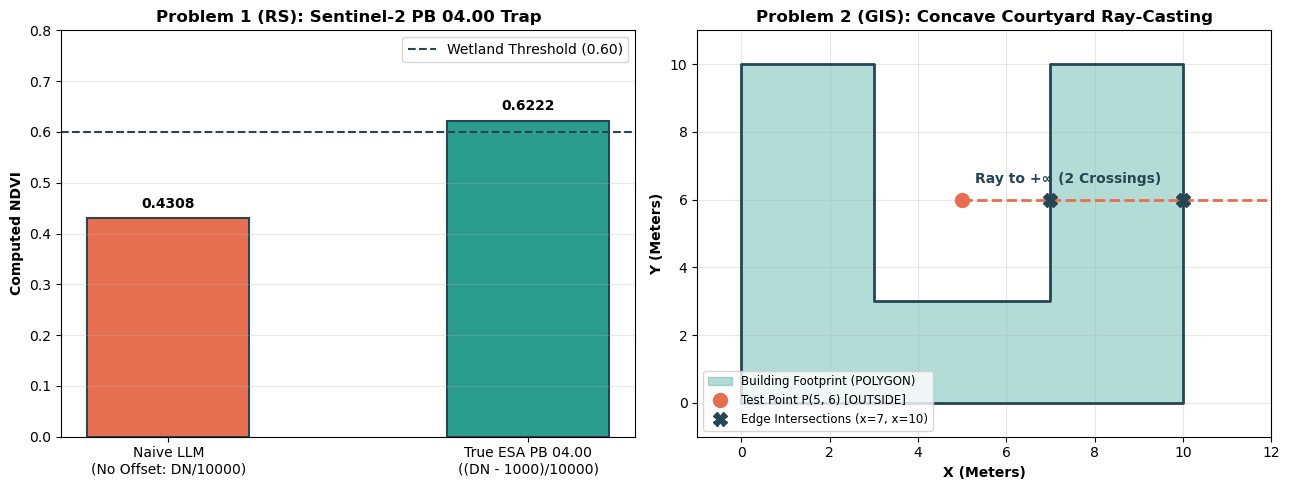

In [7]:

# ==============================================================================
print("\n" + "="*75)
print("CELL 5: PROBLEM 4 (GEODESY & ADJUSTMENT - 10% WEIGHT) GROUND TRUTH")
print("Weighted Least-Squares Leveling (Ax = L + v, p_i = 1 / S_i)")
print("="*75)

H_A = 100.000
dh1, S1 = 14.280, 4.0  # Route 1: +14.280m over 4.0 km
dh2, S2 = 14.200, 1.0  # Route 2: +14.200m over 1.0 km

L = np.array([[H_A + dh1], [H_A + dh2]]) # Observation vector [114.280, 114.200]^T
A = np.array([[1.0], [1.0]])             # Design matrix

# True Geodetic Weight Matrix: P = diag(1/S1, 1/S2)
P_true = np.diag([1.0 / S1, 1.0 / S2])
x_hat_true = np.linalg.inv(A.T @ P_true @ A) @ (A.T @ P_true @ L)
v_true = A @ x_hat_true - L

# LLM Trap A: Unweighted / Equal Weights (Simple Mean)
x_hat_equal = np.mean(L)

# LLM Trap B: Inverted Weights (Weighting proportional to distance S_i)
P_inverted = np.diag([S1, S2])
x_hat_inverted = np.linalg.inv(A.T @ P_inverted @ A) @ (A.T @ P_inverted @ L)

print(f"Route 1 Obs: {L[0,0]:.4f} m (S1 = {S1} km -> True Weight p1 = {1/S1:.2f})")
print(f"Route 2 Obs: {L[1,0]:.4f} m (S2 = {S2} km -> True Weight p2 = {1/S2:.2f})")
print(f"[TRUE LEAST-SQUARES ELEVATION H_B] = {x_hat_true[0,0]:.4f} meters")
print(f"  -> Residuals: v1 = {v_true[0,0]:+.4f} m, v2 = {v_true[1,0]:+.4f} m")
print(f"[LLM TRAP A: Equal Weights Mean]   = {x_hat_equal:.4f} meters")
print(f"[LLM TRAP B: Weighting by S_i]     = {x_hat_inverted[0,0]:.4f} meters")

# ==============================================================================
# GENERATE VISUAL DIAGNOSTIC FIGURE FOR PROBLEMS 1 & 2
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: Remote Sensing PB 04.00 Offset Impact
labels = ['Naive LLM\n(No Offset: DN/10000)', 'True ESA PB 04.00\n((DN - 1000)/10000)']
ndvi_vals = [ndvi_naive, ndvi_true]
colors = ['#E76F51', '#2A9D8F']
bars = ax1.bar(labels, ndvi_vals, color=colors, width=0.45, edgecolor='#264653', linewidth=1.5)
ax1.axhline(0.60, color='#264653', linestyle='--', linewidth=1.5, label='Wetland Threshold (0.60)')
ax1.set_ylim(0, 0.8)
ax1.set_ylabel('Computed NDVI', fontweight='bold')
ax1.set_title('Problem 1 (RS): Sentinel-2 PB 04.00 Trap', fontweight='bold')
for bar in bars:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f'{yval:.4f}', ha='center', fontweight='bold')
ax1.legend()
ax1.grid(axis='y', alpha=0.3)

# Plot 2: GIS Concave Polygon & Ray-Casting
x_poly, y_poly = poly.exterior.xy
ax2.fill(x_poly, y_poly, color='#2A9D8F', alpha=0.35, label='Building Footprint (POLYGON)')
ax2.plot(x_poly, y_poly, color='#264653', linewidth=2)
ax2.plot(5, 6, 'o', color='#E76F51', markersize=10, label='Test Point P(5, 6) [OUTSIDE]')
ax2.annotate('Ray to +∞ (2 Crossings)', xy=(10, 6), xytext=(5.3, 6.5),
             fontweight='bold', color='#264653')
ax2.plot([5, 12], [6, 6], '--', color='#E76F51', linewidth=2)
ax2.plot([7, 10], [6, 6], 'X', color='#264653', markersize=10, label='Edge Intersections (x=7, x=10)')
ax2.set_xlim(-1, 12)
ax2.set_ylim(-1, 11)
ax2.set_xlabel('X (Meters)', fontweight='bold')
ax2.set_ylabel('Y (Meters)', fontweight='bold')
ax2.set_title('Problem 2 (GIS): Concave Courtyard Ray-Casting', fontweight='bold')
ax2.legend(loc='lower left', fontsize=8.5)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()